# 05 · Risque de départ des clients (question 5)

Atelier Saint-Honoré · Lot 3 · branche `lot3-churn-appels`

## La question posée par la direction

> Un client qui ne revient pas en six mois est perdu neuf fois sur dix. On veut le repérer avant, pendant qu'un vendeur peut encore l'appeler.

## Comment nous la comprenons

La direction veut une liste de clients « à risque » avant qu'ils ne disparaissent. Il faut donc estimer, pour chaque client, la probabilité qu'il ne revienne pas dans les six mois.

Dans le fichier, nous savons déjà qui est revenu et qui ne l'est pas. Nous pouvons donc apprendre à partir du passé : c'est une classification supervisée à deux classes (parti / revenu).

## Méthodes choisies, et pourquoi

Nous comparons trois méthodes de classification vues en cours :

- **Régression logistique** : simple, elle donne directement une probabilité et on voit dans quel sens chaque variable joue. C'est notre modèle de référence.
- **Arbre de décision** : il produit des règles faciles à lire (par exemple « peu d'achats et beaucoup de SAV, donc risque fort »), mais il est instable.
- **Forêt aléatoire** : une moyenne de nombreux arbres. Souvent plus précise, mais plus difficile à expliquer à un directeur commercial.

Pourquoi pas les autres méthodes du cours :

- La régression linéaire prédit un montant, pas une réponse de type oui/non.
- K-means, CAH et ACP cherchent des groupes sans réponse connue. Ici nous avons la réponse, ce serait dommage de ne pas s'en servir (ces méthodes servent en Q7 pour la segmentation).

Pour choisir le meilleur modèle, nous ne regardons pas seulement le pourcentage de bonnes réponses. Si la plupart des clients se comportent pareil, un modèle paresseux aurait l'air bon sans rien repérer. Nous utilisons donc le **PR-AUC** (qualité du compromis précision / rappel) et le **ROC-AUC**, mesurés par validation croisée.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             average_precision_score, classification_report,
                             roc_auc_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
sns.set_theme(style="whitegrid")

def norm(s):
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()

def trouver_racine():
    """Remonte depuis le dossier du notebook jusqu'à la racine du projet."""
    p = Path.cwd().resolve()
    for d in [p, *p.parents]:
        if (d / ".git").exists() or (d / "SaintHonore_clients.csv").exists() or (d / "data").exists():
            return d
    return p

RACINE = trouver_racine()
DOSSIER_FIG = RACINE / "reports" / "figures"
DOSSIER_FIG.mkdir(parents=True, exist_ok=True)

## 1. Chargement des données

On utilise de préférence le fichier nettoyé du Membre 1 (`clients_clean.csv`). S'il n'existe pas encore dans le dépôt, le notebook repart du fichier brut `SaintHonore_clients.csv` (jamais modifié) et applique lui-même un nettoyage minimal : conversion des centimes en euros, puis, plus bas, suppression des doublons et des valeurs négatives.

In [2]:
propres = [RACINE / "data" / "processed" / "clients_clean.csv", RACINE / "clients_clean.csv"]
bruts = [RACINE / "data" / "raw" / "SaintHonore_clients.csv", RACINE / "SaintHonore_clients.csv"]

chemin_propre = next((p for p in propres if p.exists()), None)
chemin_brut = next((p for p in bruts if p.exists()), None)

if chemin_propre is not None:
    df = pd.read_csv(chemin_propre, sep=None, engine="python")
    print("Source : fichier nettoyé du Membre 1 ->", chemin_propre)
elif chemin_brut is not None:
    df = pd.read_csv(chemin_brut, sep=None, engine="python")
    print("Source : fichier brut ->", chemin_brut, "(nettoyage minimal fait ici)")
    for c in [c for c in df.columns if "centime" in norm(c)]:
        df[c.lower().replace("centimes", "eur")] = df[c] / 100
        df = df.drop(columns=c)
else:
    raise FileNotFoundError("Ni clients_clean.csv ni SaintHonore_clients.csv trouvés dans le dépôt.")

print(df.shape)
df.head()

Source : fichier brut -> /tmp/flat/SaintHonore_clients.csv (nettoyage minimal fait ici)
(770, 13)


,client_id,boutique_principale,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav,carte_fidelite,canal_prefere,pays_residence,montant_prochain_achat_eur,est_revenu_6m,montant_total_eur
0,CT80059,BT15,4.0,4.0,1468.0,0,0,aucune,en ligne,USA,725.0,oui,5872.0
1,CT80578,BT28,80.0,3.0,1235.0,1,1,argent,boutique,France,1479.0,oui,3705.0
2,CT80256,BT27,43.0,1.0,1814.0,0,2,or,boutique,France,2307.0,oui,1814.0
3,CT80098,BT16,1.0,1.0,1795.0,0,0,or,boutique,Italie,1820.0,non,1795.0
4,CT80362,BT31,51.0,3.0,2022.0,0,0,argent,boutique,Chine,1201.0,oui,6066.0


In [3]:
df.info()
print()
print("Valeurs manquantes par colonne :")
print(df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 770 entries, 0 to 769
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   client_id                   770 non-null    str    
 1   boutique_principale         770 non-null    str    
 2   anciennete_mois             770 non-null    float64
 3   nb_achats_12m               770 non-null    float64
 4   panier_moyen_eur            748 non-null    float64
 5   retours                     770 non-null    int64  
 6   demandes_sav                770 non-null    int64  
 7   carte_fidelite              748 non-null    str    
 8   canal_prefere               770 non-null    str    
 9   pays_residence              770 non-null    str    
 10  montant_prochain_achat_eur  770 non-null    float64
 11  est_revenu_6m               770 non-null    str    
 12  montant_total_eur           770 non-null    float64
dtypes: float64(5), int64(2), str(6)
memory usage: 

## 2. Repérer les colonnes importantes

Les noms de colonnes peuvent varier selon le nettoyage. Le code ci-dessous les retrouve tout seul. **Vérifie la sortie** et corrige à la main si une colonne est fausse ou vaut `None`.

In [4]:
def norm(s):
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()

def trouver(*mots):
    for c in df.columns:
        if all(m in norm(c) for m in mots):
            return c
    return None

COL_CIBLE = trouver("revenu")          # "est-il revenu dans les six mois ?"
# Colonnes qui décrivent le futur (montant du prochain achat et tout ce qui en est dérivé,
# par exemple "rapport_prochain" ou "recule") : piège, voir plus bas
COLS_FUTUR = [c for c in df.columns if any(m in norm(c) for m in ("prochain", "recule"))]
COL_BOUTIQUE = trouver("boutique")     # boutique principale
COL_ID = next((c for c in df.columns
               if norm(c) in ("id", "client_id", "id_client", "idclient", "client")), None)

# Si besoin, corrige ici à la main, par exemple :
# COL_CIBLE = "revenu_6m"

print("Colonne cible      :", COL_CIBLE)
print("Colonnes écartées (futur) :", COLS_FUTUR)
print("Colonne boutique   :", COL_BOUTIQUE)
print("Colonne identifiant:", COL_ID)
assert COL_CIBLE is not None, "Cible introuvable : renseigne COL_CIBLE à la main."

Colonne cible      : est_revenu_6m
Colonnes écartées (futur) : ['montant_prochain_achat_eur']
Colonne boutique   : boutique_principale
Colonne identifiant: client_id


## 3. Construire la variable à prédire

On retire d'abord les clients en double et les valeurs négatives impossibles (garde-fous). Nous voulons ensuite repérer les clients qui **partent**. Nous créons donc `depart` : 1 si le client n'est pas revenu dans les six mois, 0 s'il est revenu.

In [5]:
def en_binaire(s):
    if s.dtype == bool:
        return s.astype(int)
    if pd.api.types.is_numeric_dtype(s):
        return (s > 0).astype(int)
    vrai = {"oui", "yes", "true", "vrai", "1", "o", "y"}
    return s.astype(str).str.strip().str.lower().isin(vrai).astype(int)

# Garde-fous (normalement déjà faits par le Membre 1) : doublons et valeurs négatives.
# Un client en double pourrait se retrouver à la fois dans l'entraînement et dans le test,
# ce qui rendrait les résultats trop beaux.
avant = len(df)
df = df.drop_duplicates()
if COL_ID is not None:
    df = df.drop_duplicates(subset=COL_ID)
print(f"{avant - len(df)} lignes en double supprimées ({len(df)} clients uniques)")
for c in df.select_dtypes(include="number").columns:
    if c != COL_CIBLE and (df[c] < 0).any():
        print(f"{c} : {(df[c] < 0).sum()} valeurs négatives mises en manquant")
        df.loc[df[c] < 0, c] = np.nan

df = df[df[COL_CIBLE].notna()].copy()
df["depart"] = 1 - en_binaire(df[COL_CIBLE])

if COL_ID is None:
    COL_ID = "client_id"
    df[COL_ID] = [f"C{i:04d}" for i in range(len(df))]

taux_depart = df["depart"].mean()
print(f"{len(df)} clients, dont {df['depart'].sum()} partis : taux de départ = {taux_depart:.1%}")

70 lignes en double supprimées (700 clients uniques)
panier_moyen_eur : 3 valeurs négatives mises en manquant
700 clients, dont 412 partis : taux de départ = 58.9%


## 4. Le piège à éviter : utiliser une information du futur

La colonne « montant du prochain achat » décrit **ce que le client dépensera plus tard**. Au moment où le vendeur doit décider d'appeler, cette information n'existe pas. L'utiliser reviendrait à donner au modèle une information du futur (c'est une **fuite d'information**) : les résultats seraient flatteurs, mais impossibles à reproduire en vrai. C'est d'ailleurs la variable à prédire de la question 3.

Nous l'enlevons donc des variables explicatives, ainsi que toutes les colonnes construites à partir de lui (par exemple `rapport_prochain`) : elles portent la même information du futur. Nous enlevons aussi l'identifiant et la réponse elle-même.

Nous gardons aussi la boutique de côté pour le modèle : avec environ 30 clients par boutique, elle ajouterait surtout du bruit. Elle nous servira au notebook 06 pour répartir les appels.

In [6]:
UTILISER_BOUTIQUE = False   # mettre True pour tester l'effet de la boutique

a_exclure = [c for c in [COL_ID, COL_CIBLE, "depart"] if c] + COLS_FUTUR
if not UTILISER_BOUTIQUE and COL_BOUTIQUE:
    a_exclure.append(COL_BOUTIQUE)

colonnes_bool = df.select_dtypes(include="bool").columns
df[colonnes_bool] = df[colonnes_bool].astype(int)

variables = [c for c in df.columns if c not in a_exclure]
X = df[variables]
y = df["depart"]

cols_num = X.select_dtypes(include="number").columns.tolist()
cols_cat = [c for c in X.columns if c not in cols_num]

print("Variables numériques  :", cols_num)
print("Variables catégorielles:", cols_cat)

Variables numériques  : ['anciennete_mois', 'nb_achats_12m', 'panier_moyen_eur', 'retours', 'demandes_sav', 'montant_total_eur']
Variables catégorielles: ['carte_fidelite', 'canal_prefere', 'pays_residence']


## 5. Regarder les données avant de modéliser

Premier coup d'œil : le taux de départ change-t-il selon les catégories de clients ?

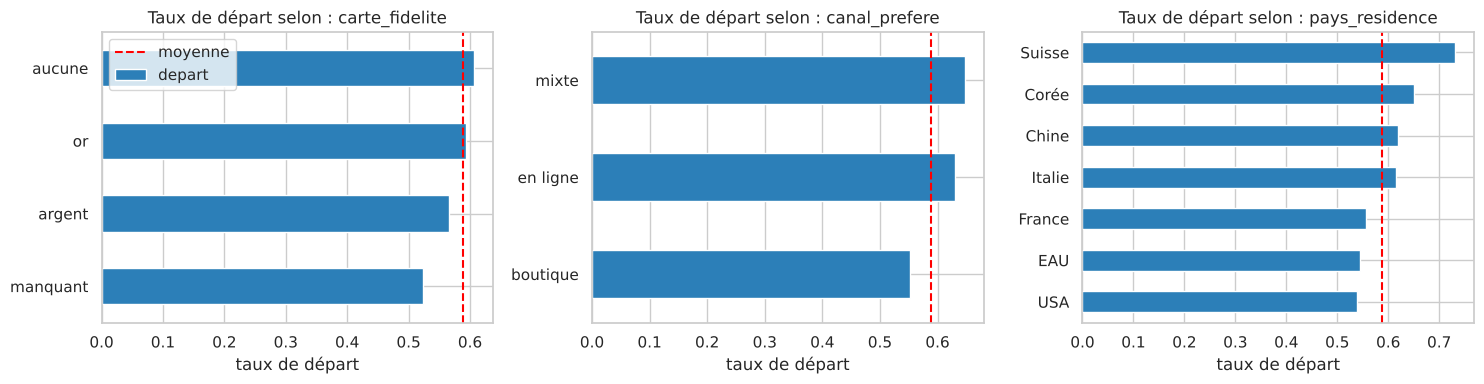

In [7]:
cats_a_tracer = [c for c in cols_cat if df[c].nunique() <= 8][:4]

if cats_a_tracer:
    fig, axes = plt.subplots(1, len(cats_a_tracer), figsize=(5 * len(cats_a_tracer), 4), squeeze=False)
    for ax, c in zip(axes[0], cats_a_tracer):
        taux = df.assign(**{c: df[c].fillna("manquant")}).groupby(c)["depart"].mean().sort_values()
        taux.plot.barh(ax=ax, color="#2c7fb8")
        ax.axvline(taux_depart, color="red", linestyle="--", label="moyenne")
        ax.set_title(f"Taux de départ selon : {c}")
        ax.set_xlabel("taux de départ")
        ax.set_ylabel("")
    axes[0][0].legend()
    plt.tight_layout()
    plt.savefig(DOSSIER_FIG / "lot3_depart_par_categorie.png", dpi=150)
    plt.show()

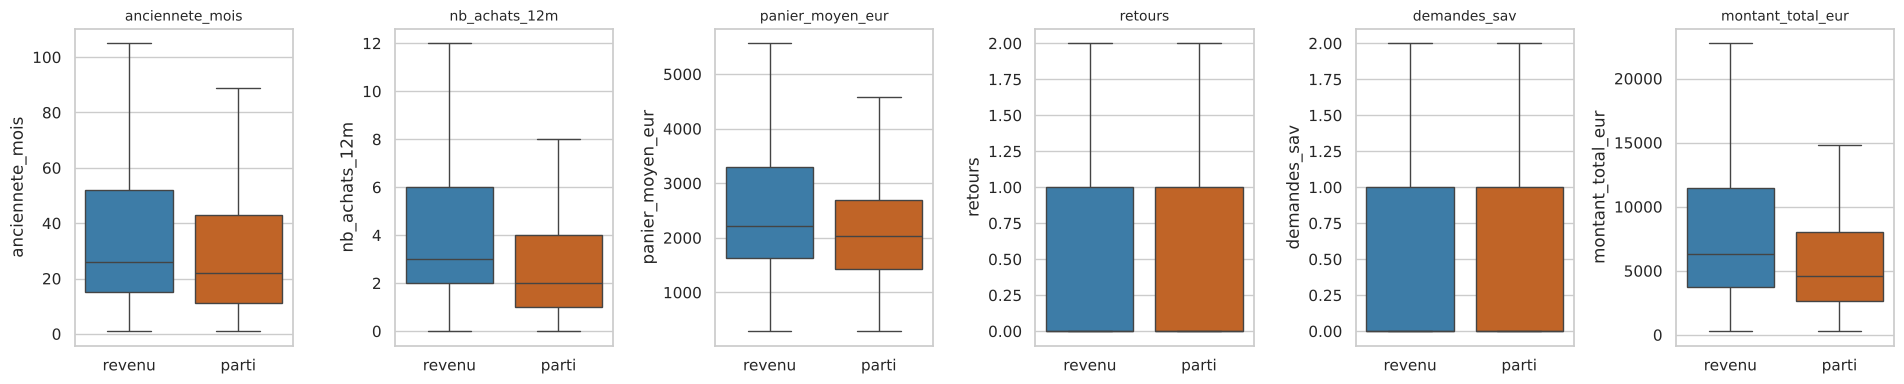

In [8]:
nums_a_tracer = cols_num[:6]
fig, axes = plt.subplots(1, len(nums_a_tracer), figsize=(3.2 * len(nums_a_tracer), 4), squeeze=False)
for ax, c in zip(axes[0], nums_a_tracer):
    sns.boxplot(data=df, x="depart", y=c, ax=ax, palette=["#2c7fb8", "#d95f0e"], showfliers=False)
    ax.set_xticklabels(["revenu", "parti"])
    ax.set_xlabel("")
    ax.set_title(c, fontsize=10)
plt.tight_layout()
plt.savefig(DOSSIER_FIG / "lot3_variables_numeriques.png", dpi=150)
plt.show()

## 6. Préparation des variables

- Valeurs manquantes : médiane pour les nombres, une catégorie « manquant » pour les textes (on ne supprime pas de clients, il n'y en a pas assez).
- Les montants sont très étalés (quelques très gros clients) : on applique un logarithme (`log1p`) pour les resserrer, puis un `RobustScaler` qui met les nombres à la même échelle tout en résistant aux valeurs extrêmes (erreurs de saisie traitées en Q9).
- Les catégories sont transformées en colonnes 0/1 (one-hot).

Tout est mis dans un `Pipeline` : ainsi la préparation est apprise uniquement sur les données d'entraînement, jamais sur celles du test.

In [9]:
pre_num = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                    ("scaler", RobustScaler())])
pre_cat = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="manquant")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])

preparation = ColumnTransformer([("num", pre_num, cols_num),
                                 ("cat", pre_cat, cols_cat)])

modeles = {
    "Régression logistique": LogisticRegression(max_iter=2000, random_state=SEED),
    "Arbre de décision": DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=SEED),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                              random_state=SEED, n_jobs=-1),
}

## 7. Découpage entraînement / test

Nous mettons 20 % des clients de côté. Le découpage est stratifié : la part de départs est la même dans les deux jeux.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f"Entraînement : {len(X_train)} clients ({y_train.mean():.1%} de départs)")
print(f"Test         : {len(X_test)} clients ({y_test.mean():.1%} de départs)")

Entraînement : 560 clients (58.9% de départs)
Test         : 140 clients (58.6% de départs)


## 8. Comparaison des trois modèles (validation croisée)

On compare les modèles sur l'entraînement uniquement, en 5 découpages. Le test reste intact pour la fin.

Critère de choix : le **PR-AUC**, car notre objectif (Q6) est d'appeler des gens qui partiront vraiment, donc d'avoir une bonne précision. Si la régression logistique est à moins de 0,01 du meilleur modèle, nous la gardons : elle est plus simple à expliquer.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
           "Précision (seuil 0,5)": "precision", "Rappel (seuil 0,5)": "recall"}

resultats = {}
for nom, modele in modeles.items():
    pipe = Pipeline([("prep", clone(preparation)), ("modele", modele)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    resultats[nom] = {k: res[f"test_{k}"].mean() for k in scoring}

tableau = pd.DataFrame(resultats).T.round(3)
tableau

,ROC-AUC,PR-AUC,"Précision (seuil 0,5)","Rappel (seuil 0,5)"
Régression logistique,0.617,0.681,0.648,0.794
Arbre de décision,0.551,0.624,0.611,0.739
Forêt aléatoire,0.624,0.698,0.638,0.827


In [12]:
meilleur = tableau["PR-AUC"].idxmax()
choix = meilleur
if tableau.loc["Régression logistique", "PR-AUC"] >= tableau.loc[meilleur, "PR-AUC"] - 0.01:
    choix = "Régression logistique"

print(f"Meilleur PR-AUC       : {meilleur} ({tableau.loc[meilleur, 'PR-AUC']})")
print(f"Modèle retenu (final) : {choix}")

Meilleur PR-AUC       : Forêt aléatoire (0.698)
Modèle retenu (final) : Forêt aléatoire


## 9. Évaluation du modèle retenu sur le jeu de test

On entraîne le modèle choisi sur tout l'entraînement, puis on le juge sur les clients qu'il n'a jamais vus.

In [13]:
modele_final = Pipeline([("prep", clone(preparation)), ("modele", clone(modeles[choix]))])
modele_final.fit(X_train, y_train)

proba_test = modele_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)

roc = roc_auc_score(y_test, proba_test)
pr = average_precision_score(y_test, proba_test)
print(f"ROC-AUC (test) : {roc:.3f}")
print(f"PR-AUC  (test) : {pr:.3f}   (un modèle au hasard donnerait environ {y_test.mean():.3f})")
print()
print(classification_report(y_test, pred_test, target_names=["revenu", "parti"], zero_division=0))

ROC-AUC (test) : 0.592
PR-AUC  (test) : 0.680   (un modèle au hasard donnerait environ 0.586)

              precision    recall  f1-score   support

      revenu       0.48      0.21      0.29        58
       parti       0.60      0.84      0.70        82

    accuracy                           0.58       140
   macro avg       0.54      0.52      0.49       140
weighted avg       0.55      0.58      0.53       140



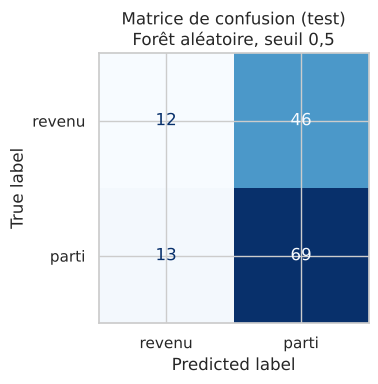

In [14]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["revenu", "parti"], cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Matrice de confusion (test)\n{choix}, seuil 0,5")
plt.tight_layout()
plt.savefig(DOSSIER_FIG / "lot3_matrice_confusion.png", dpi=150)
plt.show()

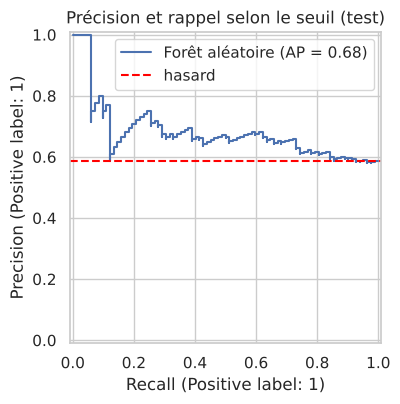

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=ax, name=choix)
ax.axhline(y_test.mean(), color="red", linestyle="--", label="hasard")
ax.set_title("Précision et rappel selon le seuil (test)")
ax.legend()
plt.tight_layout()
plt.savefig(DOSSIER_FIG / "lot3_courbe_precision_rappel.png", dpi=150)
plt.show()

## 10. Qu'est-ce qui pousse un client à partir ?

Nous mesurons l'importance de chaque variable par permutation : on mélange une colonne au hasard et on regarde de combien la qualité du modèle baisse. Plus elle baisse, plus la variable compte.

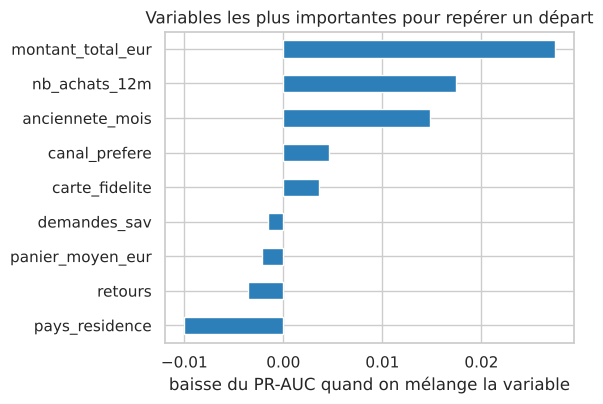

montant_total_eur    0.0275
nb_achats_12m        0.0174
anciennete_mois      0.0148
canal_prefere        0.0046
carte_fidelite       0.0036
dtype: float64

In [16]:
imp = permutation_importance(modele_final, X_test, y_test, scoring="average_precision",
                             n_repeats=20, random_state=SEED)
importance = (pd.Series(imp.importances_mean, index=X_test.columns)
              .sort_values(ascending=False))

top = importance.head(10)[::-1]
fig, ax = plt.subplots(figsize=(6, 4.2))
top.plot.barh(ax=ax, color="#2c7fb8")
ax.set_title("Variables les plus importantes pour repérer un départ")
ax.set_xlabel("baisse du PR-AUC quand on mélange la variable")
plt.tight_layout()
plt.savefig(DOSSIER_FIG / "lot3_importance_variables.png", dpi=150)
plt.show()

importance.head(5).round(4)

In [17]:
# Dans quel sens joue chaque variable importante ? (lecture simple)
for var in importance.head(4).index:
    if var in cols_num:
        print(f"{var} (moyenne) :")
        print(df.groupby("depart")[var].mean().rename({0: "revenus", 1: "partis"}).round(2).to_string())
    else:
        print(f"{var} (taux de départ par catégorie) :")
        print(df.assign(**{var: df[var].fillna("manquant")}).groupby(var)["depart"].mean().round(2).to_string())
    print()

montant_total_eur (moyenne) :
depart
revenus    16816.14
partis      9779.72

nb_achats_12m (moyenne) :
depart
revenus    4.36
partis     3.16

anciennete_mois (moyenne) :
depart
revenus    34.09
partis     28.45

canal_prefere (taux de départ par catégorie) :
canal_prefere
boutique    0.55
en ligne    0.63
mixte       0.65



## 11. Probabilités de départ pour tous les clients

Le notebook 06 a besoin d'une probabilité de départ pour **chaque** client. Si on utilisait le modèle entraîné sur tous les clients, la probabilité d'un client serait biaisée (le modèle l'a déjà vu). Nous utilisons donc des prédictions « hors échantillon » : chaque client est prédit par un modèle qui ne l'a pas vu pendant son entraînement.

In [18]:
proba_oof = cross_val_predict(
    Pipeline([("prep", clone(preparation)), ("modele", clone(modeles[choix]))]),
    X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    method="predict_proba")[:, 1]

sortie = pd.DataFrame({
    "client_id": df[COL_ID].values,
    "boutique": df[COL_BOUTIQUE].values if COL_BOUTIQUE else "inconnue",
    "depart": y.values,
    "proba_depart": proba_oof.round(4),
})

(RACINE / "data" / "processed").mkdir(parents=True, exist_ok=True)
sortie.to_csv(RACINE / "data" / "processed" / "clients_churn_proba.csv", index=False)

print(f"PR-AUC hors échantillon (tous clients) : {average_precision_score(y, proba_oof):.3f}")
print(f"ROC-AUC hors échantillon (tous clients): {roc_auc_score(y, proba_oof):.3f}")

# Modèle final entraîné sur tous les clients (pour de futurs clients)
(RACINE / "models").mkdir(exist_ok=True)
joblib.dump(clone(modele_final).fit(X, y), RACINE / "models" / "churn_model.joblib")
sortie.head()

PR-AUC hors échantillon (tous clients) : 0.672
ROC-AUC hors échantillon (tous clients): 0.593


,client_id,boutique,depart,proba_depart
0,CT80059,BT15,0,0.6677
1,CT80578,BT28,0,0.5185
2,CT80256,BT27,0,0.6897
3,CT80098,BT16,1,0.7268
4,CT80362,BT31,0,0.5157


## 12. Réponse à la direction

In [19]:
top3 = ", ".join(importance.head(3).index)
if roc >= 0.75:
    niveau = "nettement mieux que le hasard"
elif roc >= 0.65:
    niveau = "mieux que le hasard"
else:
    niveau = "un peu mieux que le hasard seulement : le départ est difficile à prévoir avec ces variables"

print(f"""Sur {len(df)} clients, {taux_depart:.0%} ne sont pas revenus dans les six mois.
Nous avons comparé trois modèles et retenu : {choix}.
Sur des clients qu'il n'a jamais vus, il classe les clients à risque {niveau}
(PR-AUC {pr:.2f} contre {y_test.mean():.2f} au hasard, ROC-AUC {roc:.2f}).
Les signaux qui comptent le plus sont : {top3}.
Le montant du prochain achat a été volontairement écarté : il décrit le futur, on ne le connaît pas au moment d'appeler.
Chaque client reçoit donc une probabilité de départ, utilisée au notebook 06 pour décider qui appeler.""")

Sur 700 clients, 59% ne sont pas revenus dans les six mois.
Nous avons comparé trois modèles et retenu : Forêt aléatoire.
Sur des clients qu'il n'a jamais vus, il classe les clients à risque un peu mieux que le hasard seulement : le départ est difficile à prévoir avec ces variables
(PR-AUC 0.68 contre 0.59 au hasard, ROC-AUC 0.59).
Les signaux qui comptent le plus sont : montant_total_eur, nb_achats_12m, anciennete_mois.
Le montant du prochain achat a été volontairement écarté : il décrit le futur, on ne le connaît pas au moment d'appeler.
Chaque client reçoit donc une probabilité de départ, utilisée au notebook 06 pour décider qui appeler.


## Limites à garder en tête

- Le fichier est petit (quelques centaines de clients) : les résultats peuvent bouger d'un découpage à l'autre, d'où l'usage de la validation croisée.
- Le modèle repère des clients **à risque**, il ne dit pas pourquoi un client part précisément.
- Une probabilité n'est pas une certitude : un client à 80 % de risque revient quand même 2 fois sur 10.
- Les erreurs de saisie et les valeurs extrêmes (Q9) peuvent légèrement modifier les résultats si le Membre 1 les corrige plus tard : il faudra relancer le notebook (Kernel, Restart & Run All).